# LA LA Stay | Airbnb Pricing Analysis
### EDA visual + regresión + clasificación + entrega final

**Objetivo:** explicar qué características se relacionan con los precios de Airbnb, probar dos modelos y entregar los archivos para el dashboard.

Usamos exclusivamente la **nueva base `listings_clean (2).xlsx`**. Los CSV que descargamos del primer notebook pertenecen a una versión anterior, por eso no se mezclan.

**Ruta:** cargar → filtrar → gráficas → regresión 80/20 → clasificación → pruebas editables → **un solo ZIP con todos los archivos individuales**.

> El R² es una métrica de desempeño, no una garantía de precio óptimo ni de reservas. Los filtros de outliers y estancias largas se documentan y también evaluamos la muestra sin ellos.

## 1 · Preparar Colab
Necesitamos pandas para la base, matplotlib para las gráficas y scikit-learn para los modelos. Ejecutamos las celdas en orden.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', 45)
print('Libraries ready')

Libraries ready


In [ ]:
# Rutas del proyecto: funciona desde cualquier carpeta dentro del repositorio
from pathlib import Path

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / 'data' / 'clean').is_dir():
            return folder
    return start  # Colab u otra ubicación: se usa la carpeta actual

ROOT = find_project_root()
DATA_DIR = ROOT / 'data' / 'clean'     # Excel y bases limpias
MODELS_DIR = ROOT / 'models'           # modelos .pkl entregados por el equipo (no se sobrescriben)
OUT_DIR = ROOT / 'outputs'             # todo lo que genera este notebook
OUT_DIR.mkdir(exist_ok=True)
if not DATA_DIR.is_dir():
    DATA_DIR = ROOT  # Colab: el Excel se sube a la carpeta actual
print('ROOT:', ROOT)
print('DATA_DIR:', DATA_DIR)
print('OUT_DIR:', OUT_DIR)


### 1.1 · Cargar la nueva base
**Subimos `listings_clean (2).xlsx`**, no el CSV del trabajo anterior. Leemos la hoja **Clean data**. Si ejecutamos esto otra vez, Colab puede pedir el archivo de nuevo.

In [2]:
# Los archivos se leen desde la carpeta del repositorio (ver celda de rutas arriba)
DATA_FILE = DATA_DIR / 'listings_clean (2).xlsx'
if not DATA_FILE.exists():
    # Plan B (solo Google Colab): subir el Excel a mano
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = Path(next(name for name in uploaded if name.endswith('.xlsx')))

df = pd.read_excel(DATA_FILE, sheet_name='Clean data')
print('Rows:', len(df), '| Columns:', len(df.columns))
display(df.head(3))


Saving listings_clean (2).xlsx to listings_clean (2).xlsx
Rows: 20541 | Columns: 38


,id,latitude,longitude,room_type,calculated_host_listings_count,price,price_missing,price_outlier,bedrooms,bedrooms_original,bedrooms_imputed,accommodates,neighbourhood_cleansed,neighbourhood_model,property_type,property_type_model,am_kitchen_score,am_bath_score,am_security_score,am_bedroom_score,am_outdoor_score,am_entertainment_work_score,am_access_services_score,am_views_score,am_other_score,has_ac,has_heating,has_laundry,has_parking,has_pool,has_hot_tub,has_bathtub,pets_allowed,amenities_count,amenities_empty,minimum_nights,long_stay,minimum_nights_missing
0,2708,34.09625,-118.34605,Private room,2,76.31,0,0,1,1.0,0,1,Hollywood,Hollywood,Private room in rental unit,Private room in rental unit,17,8,4,6,7,4,4,2,4,1,1,1,1,1,1,1,0,77,0,30.0,0,0
1,2732,34.00440,-118.48095,Private room,2,215.21,0,0,1,1.0,0,1,Santa Monica,Santa Monica,Private room in rental unit,Private room in rental unit,6,3,0,1,1,1,1,0,0,0,1,1,1,0,0,0,0,19,0,7.0,0,0
2,6931,34.09626,-118.34372,Private room,2,69.50,0,0,1,1.0,0,1,Hollywood,Hollywood,Private room in rental unit,Private room in rental unit,17,8,4,5,7,5,4,1,4,1,1,1,1,0,1,1,0,72,0,30.0,0,0


### 1.2 · Confirmar que el Excel es el correcto
La base nueva trae columnas preparadas por el equipo, como `neighbourhood_model` y `property_type_model`. Son diferentes a las de la base original.

In [3]:
required = [
    'id', 'price', 'price_outlier', 'long_stay',
    'bedrooms', 'accommodates',
    'neighbourhood_model', 'property_type_model',
    'calculated_host_listings_count'
]

assert all(col in df.columns for col in required), 'Revisa la hoja Clean data'
print('Duplicate IDs:', df.duplicated('id').sum())
print('Missing prices:', df['price'].isna().sum())

Duplicate IDs: 0
Missing prices: 4237


## 2 · Entender la limpieza
No basta con eliminar datos. Queremos saber **qué información falta** y **a qué población representan los resultados**.

### 2.1 · Datos faltantes
Esta gráfica indica qué columnas tienen más valores vacíos. Una columna vacía no implica automáticamente que debamos borrar toda la propiedad.

In [4]:
missing = (df.isna().mean() * 100).sort_values(ascending=False)
print('Missing price (%):', round(missing['price'], 2))
display(missing.head(10).round(2).to_frame('Missing %'))

Missing price (%): 20.63


,Missing %
price,20.63
bedrooms_original,0.28
minimum_nights,0.05
longitude,0.00
latitude,0.00
id,0.00
calculated_host_listings_count,0.00
room_type,0.00
price_outlier,0.00
price_missing,0.00


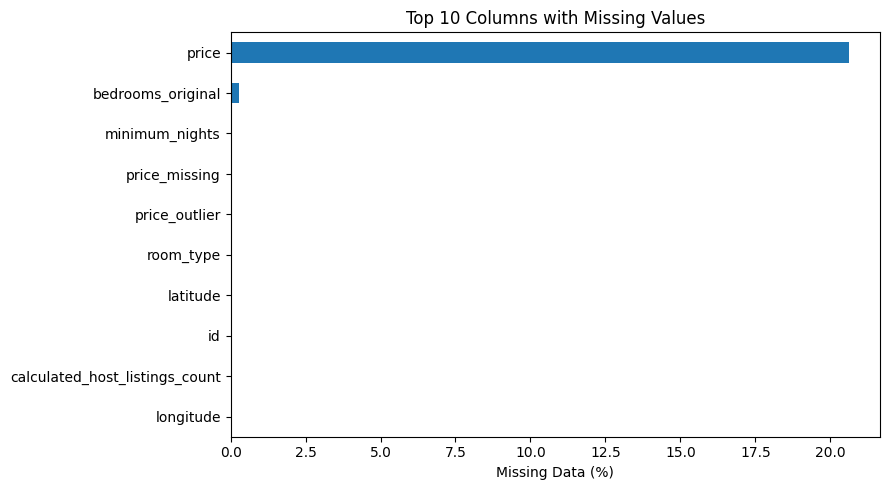

In [5]:
missing.head(10).sort_values().plot(kind='barh', figsize=(9, 5))
plt.title('Top 10 Columns with Missing Values')
plt.xlabel('Missing Data (%)')
plt.tight_layout()
plt.show()

**Lo que observamos:** la variable `price` es indispensable para entrenar una regresión, pero no tiene sentido sustituir precios faltantes con cero porque cambiaría el mercado que queremos representar.

### 2.2 · Aplicar los filtros definidos por el equipo
Para el modelo principal conservamos: hosts con 1–2 listings, precio positivo, `price_outlier = 0` y `long_stay = 0`.

Los indicadores de outliers y estancias largas **ya vienen en el Excel**. No los calculamos viendo qué R² nos convenía. Al final repetiremos una evaluación sin esas dos exclusiones.

In [6]:
original_duplicates = int(df.duplicated(subset='id').sum())
df = df.drop_duplicates(subset='id').copy()

with_price = df[df['price'] > 0].copy()
small_hosts = with_price[with_price['calculated_host_listings_count'].between(1, 2)].copy()

df_clean = small_hosts[
    (small_hosts['price_outlier'] == 0) &
    (small_hosts['long_stay'] == 0)
].copy()

print('Original:', len(df))
print('With valid price:', len(with_price))
print('Hosts with 1–2 listings:', len(small_hosts))
print('Main analysis sample:', len(df_clean))

Original: 20541
With valid price: 16304
Hosts with 1–2 listings: 16304
Main analysis sample: 14825


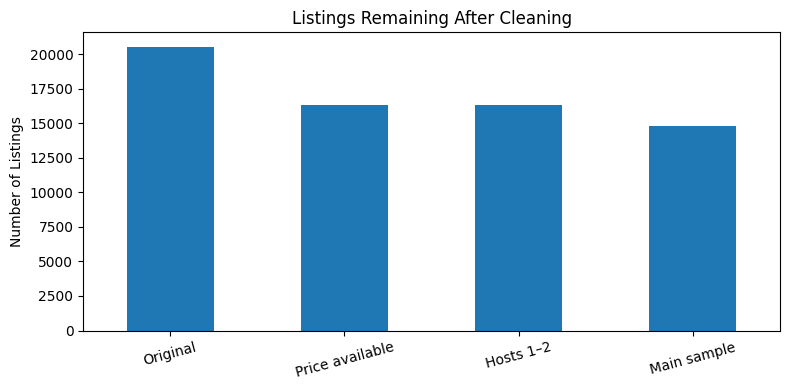

In [7]:
steps = pd.Series({
    'Original': len(df),
    'Price available': len(with_price),
    'Hosts 1–2': len(small_hosts),
    'Main sample': len(df_clean)
})
steps.plot(kind='bar', figsize=(8, 4))
plt.title('Listings Remaining After Cleaning')
plt.ylabel('Number of Listings')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Interpretación:** a partir de aquí, nuestras gráficas principales describen **el segmento filtrado**, no todos los Airbnbs de Los Ángeles. Vamos a conservar `small_hosts` para comprobar después si los resultados cambian al incluir precios extremos y estancias largas.

## 3 · Exploratory Data Analysis (EDA)
Volvemos a las visualizaciones de la primera versión. Usamos **medianas** en las comparaciones porque unos pocos precios altos pueden elevar mucho el promedio.

### 3.1 · Estadísticas de precio

In [8]:
prices = df_clean['price'].dropna()

print('Listings with price:', len(prices))
print('Mean price (USD):', round(prices.mean(), 2))
print('Median price (USD):', round(prices.median(), 2))
print('Maximum price (USD):', round(prices.max(), 2))

Listings with price: 14825
Mean price (USD): 312.23
Median price (USD): 224.13
Maximum price (USD): 2156.5


### 3.2 · Distribución de precios
Queremos saber dónde se concentra la mayoría de los anuncios, no solo cuánto cuesta el más caro.

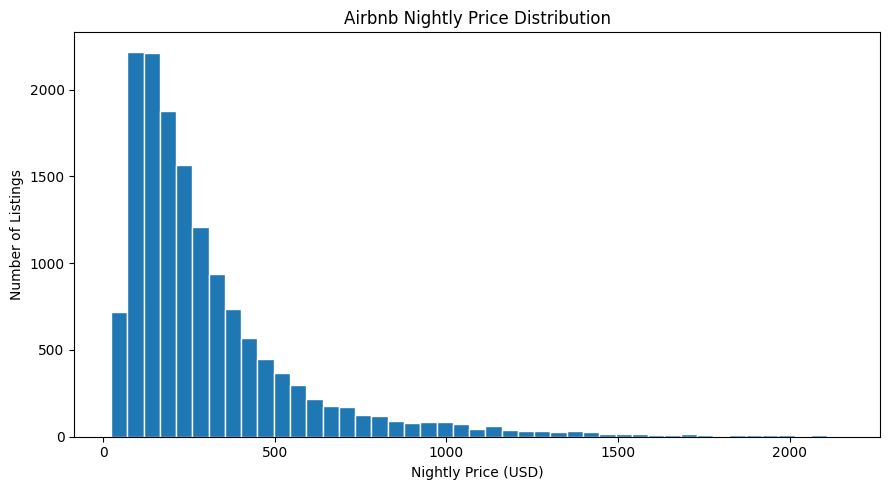

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(prices, bins=45, edgecolor='white')
plt.title('Airbnb Nightly Price Distribution')
plt.xlabel('Nightly Price (USD)')
plt.ylabel('Number of Listings')
plt.tight_layout()
plt.show()

**Interpretación:** si hay una cola larga hacia la derecha, significa que la mayoría de los precios se agrupan en valores bajos o intermedios y pocos listings cuestan mucho más.

### 3.3 · Precios por número de recámaras
Agrupamos por recámaras y mostramos solamente las categorías con al menos 30 anuncios. Así evitamos que una categoría con una sola propiedad parezca representativa.

In [10]:
by_bedrooms = df_clean.groupby('bedrooms')['price'].agg(['count', 'median'])
by_bedrooms = by_bedrooms[by_bedrooms['count'] >= 30]
display(by_bedrooms.round(2))

,count,median
bedrooms,,
0,1071,153.00
1,6983,148.10
2,3134,276.06
3,2255,415.50
4,957,554.26
5,315,716.97
6,81,900.43


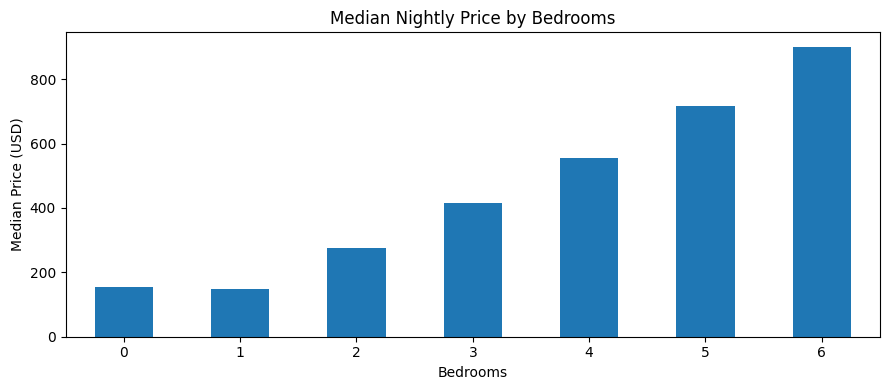

In [11]:
by_bedrooms['median'].plot(kind='bar', figsize=(9, 4))
plt.title('Median Nightly Price by Bedrooms')
plt.xlabel('Bedrooms')
plt.ylabel('Median Price (USD)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretación:** comparamos tamaños de propiedad. Una relación ascendente sugiere que las propiedades más grandes **suelen anunciarse** a precios más altos; no prueba que agregar una recámara cause ese aumento.

### 3.4 · Precios por vecindario
Tomamos los 12 vecindarios con más anuncios. Es mejor comparar zonas con suficientes registros que mostrar todas las zonas al mismo tiempo.

In [12]:
by_area = df_clean.groupby('neighbourhood_model')['price'].agg(['count', 'median'])
top_area = by_area.sort_values('count', ascending=False).head(12)
display(top_area.round(2))

,count,median
neighbourhood_model,,
Long Beach,611,295.56
Venice,602,293.34
Santa Monica,396,290.25
Hollywood,345,166.67
Downtown,319,166.77
Hollywood Hills,282,325.01
West Hollywood,272,229.41
Hollywood Hills West,263,570.00
Pasadena,259,240.00


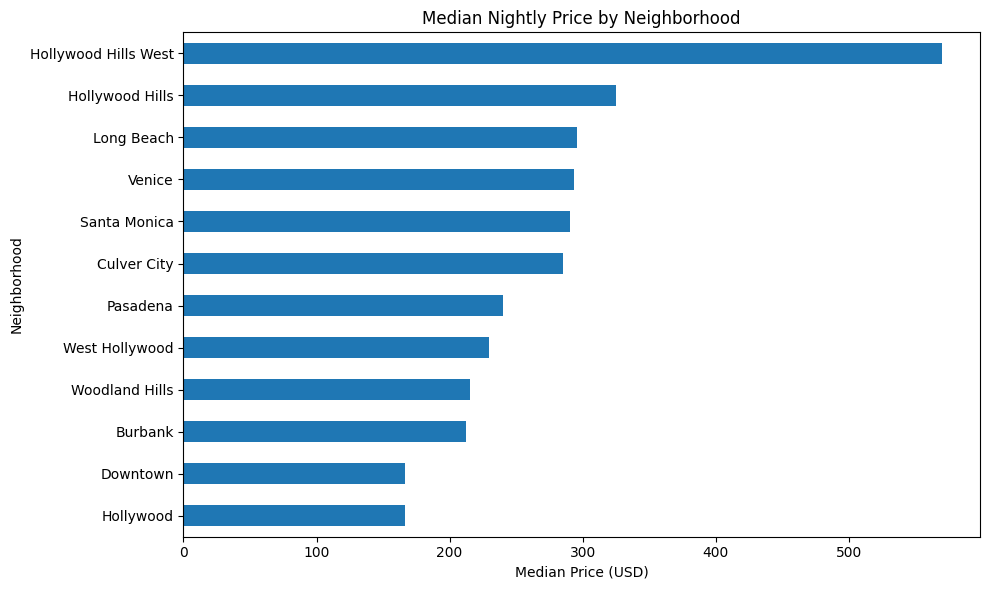

In [13]:
top_area.sort_values('median')['median'].plot(kind='barh', figsize=(10, 6))
plt.title('Median Nightly Price by Neighborhood')
plt.xlabel('Median Price (USD)')
plt.ylabel('Neighborhood')
plt.tight_layout()
plt.show()

**Interpretación:** la ubicación parece relevante cuando las medianas cambian entre vecindarios. Pero cada zona también puede tener diferentes tipos y tamaños de propiedades.

### 3.5 · Precios por tipo de propiedad
Utilizamos `property_type_model`, una versión agrupada de los tipos originales que reduce categorías demasiado específicas.

In [14]:
by_type = df_clean.groupby('property_type_model')['price'].agg(['count', 'median'])
top_types = by_type.sort_values('count', ascending=False).head(10)
display(top_types.round(2))

,count,median
property_type_model,,
Entire home,5543,369.00
Entire rental unit,2385,209.23
Entire guesthouse,1760,178.42
Private room in home,1577,106.00
Entire guest suite,658,177.62
Private room in rental unit,536,90.73
Entire condo,536,227.39
Unique private room,246,134.39
Entire townhouse,210,338.25


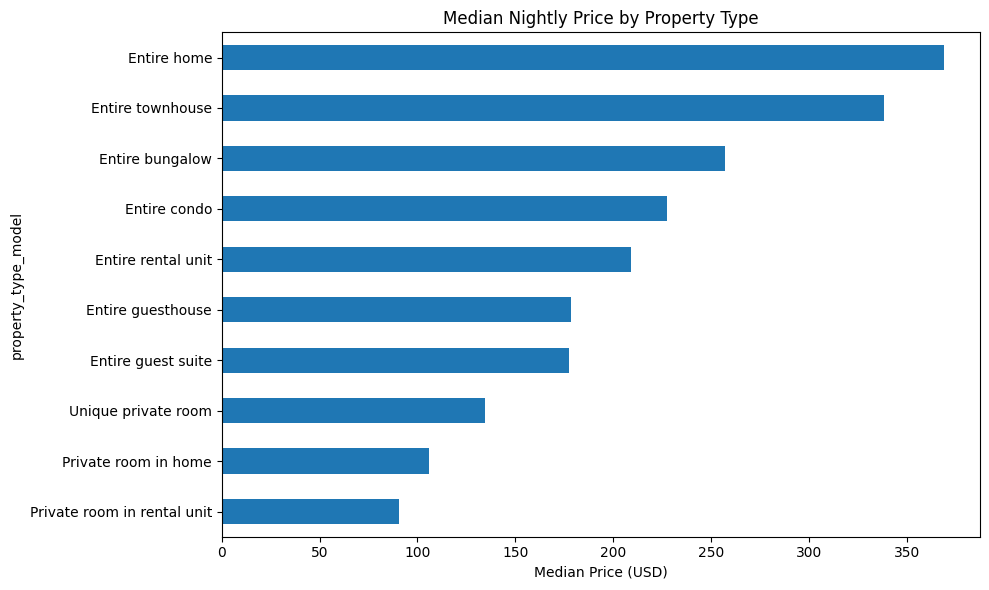

In [15]:
top_types.sort_values('median')['median'].plot(kind='barh', figsize=(10, 6))
plt.title('Median Nightly Price by Property Type')
plt.xlabel('Median Price (USD)')
plt.tight_layout()
plt.show()

**Interpretación:** no es lo mismo comparar una habitación privada con una casa completa. Por eso el tipo de propiedad es una de las cinco características del modelo.

### 3.6 · Precios por capacidad de huéspedes
Mostramos capacidades de 1 a 12 huéspedes para tener un gráfico legible.

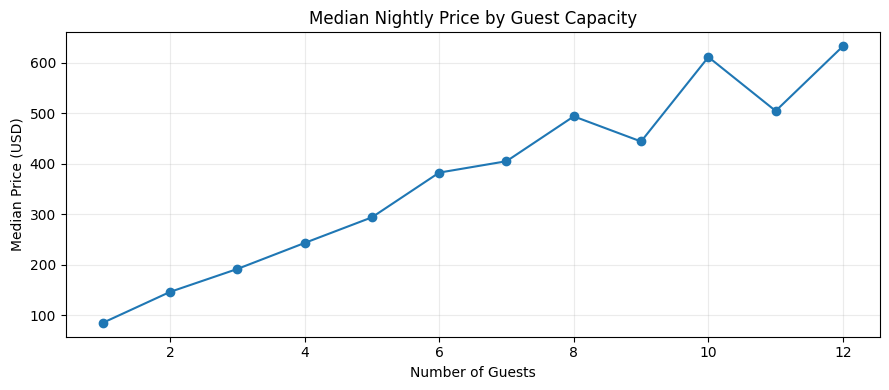

In [16]:
by_guests = (
    df_clean[df_clean['accommodates'].between(1, 12)]
    .groupby('accommodates')['price'].median()
)
by_guests.plot(marker='o', figsize=(9, 4))
plt.title('Median Nightly Price by Guest Capacity')
plt.xlabel('Number of Guests')
plt.ylabel('Median Price (USD)')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretación:** este análisis sirve para detectar si el precio se relaciona con cuántas personas caben en la propiedad; también se relaciona con el número de recámaras.

### 3.7 · ¿Cambian los precios según los servicios?
Aquí comparamos las medianas de propiedades con y sin cada amenity. **Es una comparación descriptiva, no una prueba de causalidad.**

In [17]:
amenities_to_compare = ['has_pool', 'has_parking', 'has_ac', 'has_hot_tub', 'has_bathtub']
rows = []
for amenity in amenities_to_compare:
    median_price = df_clean.groupby(amenity)['price'].median()
    rows.append({
        'Amenity': amenity.replace('has_', ''),
        'Without': median_price.get(0, np.nan),
        'With': median_price.get(1, np.nan)
    })
amenity_table = pd.DataFrame(rows).set_index('Amenity')
display(amenity_table.round(2))

,Without,With
Amenity,,
pool,214.64,271.16
parking,154.87,231.39
ac,195.00,227.88
hot_tub,211.80,315.73
bathtub,189.00,287.00


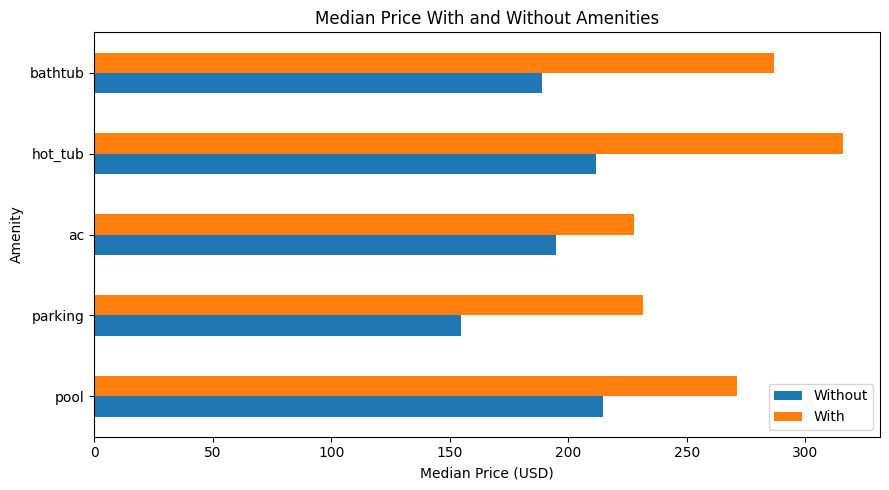

In [18]:
amenity_table.plot(kind='barh', figsize=(9, 5))
plt.title('Median Price With and Without Amenities')
plt.xlabel('Median Price (USD)')
plt.ylabel('Amenity')
plt.tight_layout()
plt.show()

**Interpretación:** un servicio puede aparecer junto con un precio más alto porque esas propiedades también están en mejores zonas o son más grandes. El modelo intentará considerar estas características al mismo tiempo.

### 3.8 · Cantidad de amenities vs. precio
La cantidad total de servicios es una manera sencilla de resumir la información. No todos los servicios tienen el mismo valor, por eso también incluiremos indicadores específicos.

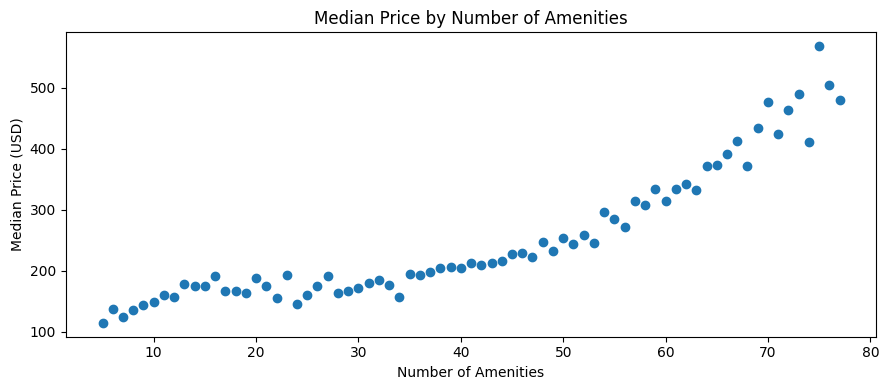

In [19]:
by_amenities = df_clean.groupby('amenities_count')['price'].agg(['count', 'median'])
by_amenities = by_amenities[by_amenities['count'] >= 30]

plt.figure(figsize=(9, 4))
plt.scatter(by_amenities.index, by_amenities['median'])
plt.title('Median Price by Number of Amenities')
plt.xlabel('Number of Amenities')
plt.ylabel('Median Price (USD)')
plt.tight_layout()
plt.show()

### 3.9 · Identificar el efecto de los precios extremos
Visualizamos lado a lado la dispersión de los precios disponibles antes y después del filtro. No cambiamos el precio: solo definimos el segmento que se usará en el modelo principal.

/tmp/ipykernel_745/2125783493.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([small_hosts['price'].dropna(), df_clean['price'].dropna()],


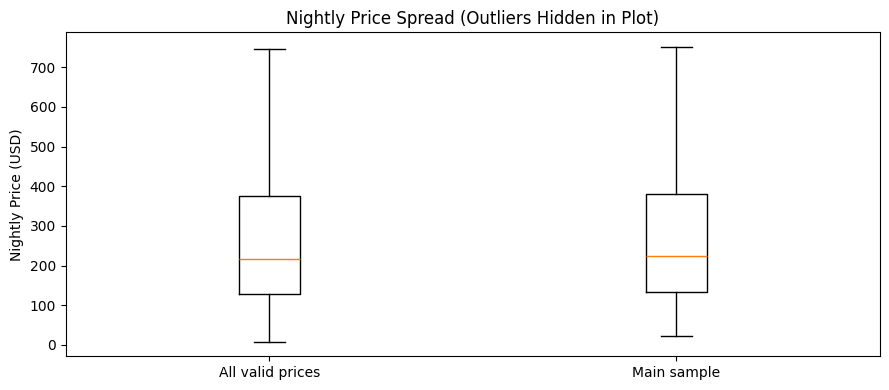

In [20]:
plt.figure(figsize=(9, 4))
plt.boxplot([small_hosts['price'].dropna(), df_clean['price'].dropna()],
            labels=['All valid prices', 'Main sample'], showfliers=False)
plt.title('Nightly Price Spread (Outliers Hidden in Plot)')
plt.ylabel('Nightly Price (USD)')
plt.tight_layout()
plt.show()

**Nota:** `showfliers=False` oculta puntos extremos solo en la **visualización**. No elimina filas ni altera los datos. El segmento usado en regresión ya se filtró en el paso 2 con las reglas del Excel.

## 4 · Regression Model
Queremos estimar el **precio publicado** por noche. Usamos únicamente las cinco características acordadas en el Project Charter: recámaras, vecindario, tipo, huéspedes y amenities.

### 4.1 · Preparar las variables
Cada amenity ocupa una o varias columnas (`am_`, `has_`, `pets_allowed`, `amenities_count`), pero sigue siendo una de las cinco características conceptuales.

In [21]:
amenity_features = sorted([
    col for col in df_clean.columns
    if col.startswith(('am_', 'has_'))
]) + ['pets_allowed', 'amenities_count']

numeric_features = ['bedrooms', 'accommodates'] + amenity_features
category_features = ['neighbourhood_model', 'property_type_model']
feature_columns = numeric_features + category_features

print('Amenity indicators:', len(amenity_features))
print('Total model columns:', len(feature_columns))

Amenity indicators: 18
Total model columns: 22


In [22]:
# Remove rows missing any required predictor (normally none in this clean Excel)
df_model = df_clean.dropna(subset=feature_columns + ['price']).copy()

X = df_model[feature_columns]
y = df_model['price']

print('Rows available for modeling:', len(df_model))
print('Target = price (USD)')

Rows available for modeling: 14825
Target = price (USD)


### 4.2 · Separar entrenamiento y prueba
El **80%** se usa para aprender patrones y el **20%** se reserva para medir qué tan bien predice el modelo propiedades que no vio.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Train:', len(X_train))
print('Test:', len(X_test))

Train: 11860
Test: 2965


### 4.3 · Convertir los textos en variables numéricas
Ridge no entiende nombres de vecindarios directamente. `OneHotEncoder` crea indicadores numéricos y `handle_unknown='ignore'` permite recibir categorías nuevas en el futuro.

In [24]:
preprocessor = ColumnTransformer([
    ('categories', OneHotEncoder(handle_unknown='ignore'), category_features)
], remainder='passthrough')

model = Pipeline([
    ('prepare', preprocessor),
    ('ridge', Ridge(alpha=1))
])
print('Ridge pipeline ready')

Ridge pipeline ready


### 4.4 · Comprobar si Ridge es una elección razonable
Probamos distintas intensidades de regularización con **validación cruzada sobre entrenamiento**. El test permanece apartado, para no escoger el modelo mirando su calificación final.

In [25]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)
cv_rows = []

for alpha in [1, 10, 100]:
    model.set_params(ridge__alpha=alpha)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='r2')
    cv_rows.append({'alpha': alpha, 'CV_R2': scores.mean()})

cv_table = pd.DataFrame(cv_rows).sort_values('CV_R2', ascending=False)
display(cv_table.round(4))

,alpha,CV_R2
0,1,0.5592
1,10,0.5590
2,100,0.5243


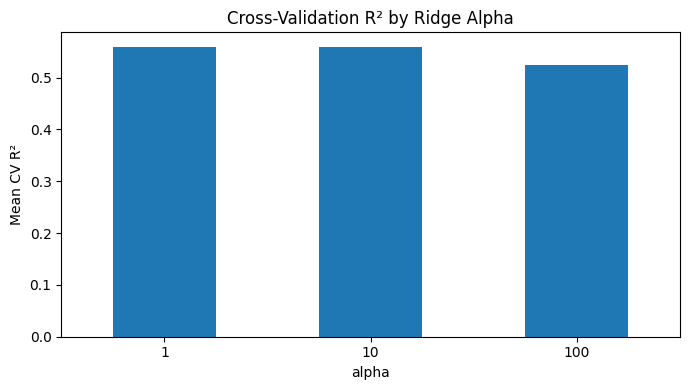

In [26]:
cv_table.plot.bar(x='alpha', y='CV_R2', legend=False, figsize=(7, 4))
plt.title('Cross-Validation R² by Ridge Alpha')
plt.ylabel('Mean CV R²')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretación:** el mejor `alpha` es el que obtuvo mayor R² promedio **solo en entrenamiento**. No es una garantía de que el R² final sea idéntico.

### 4.5 · Entrenar el modelo elegido

In [27]:
best_alpha = int(cv_table.iloc[0]['alpha'])
model.set_params(ridge__alpha=best_alpha)
model.fit(X_train, y_train)
print('Selected alpha:', best_alpha)
print('Model trained')

Selected alpha: 1
Model trained


### 4.6 · Predecir y evaluar
Calculamos MAE y RMSE en dólares; R² indica qué proporción de la variación de precios explicamos en **el conjunto de prueba**.

In [28]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('MAE: $', round(mae, 2))
print('RMSE: $', round(rmse, 2))
print('R²:', round(r2, 4))
print('R² target 0.30 reached:', r2 >= 0.30)

MAE: $ 121.99
RMSE: $ 193.93
R²: 0.5749
R² target 0.30 reached: True


**Cómo lo explicamos:** si el MAE es $120, el error absoluto promedio es aproximadamente 120 dólares por noche. **R² no es un porcentaje de predicciones correctas**. Aunque sea mayor que 0.30, las recomendaciones siguen teniendo incertidumbre.

### 4.7 · Precio real vs. predicción
Mientras más cerca esté un punto de la diagonal, más cercana fue la predicción al precio real.

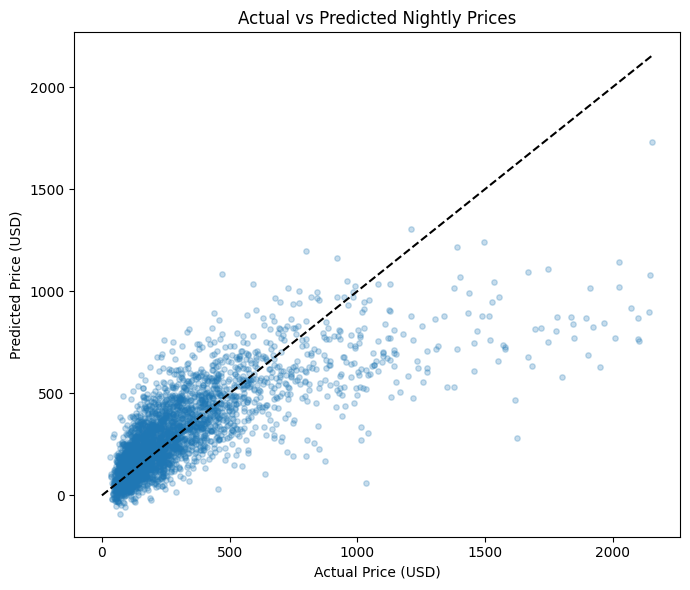

In [29]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.25, s=15)
limit = max(y_test.max(), y_pred.max())
plt.plot([0, limit], [0, limit], '--', color='black')
plt.title('Actual vs Predicted Nightly Prices')
plt.xlabel('Actual Price (USD)')
plt.ylabel('Predicted Price (USD)')
plt.tight_layout()
plt.show()

### 4.8 · Distribución de los errores
El **residuo** es `precio real - predicción`. Un residuo positivo significa que el modelo predijo menos de lo publicado.

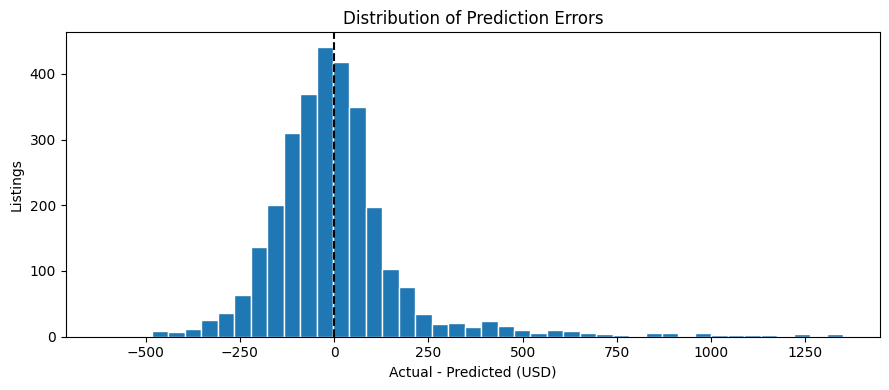

In [30]:
residuals = y_test - y_pred
plt.figure(figsize=(9, 4))
plt.hist(residuals, bins=45, edgecolor='white')
plt.axvline(0, linestyle='--', color='black')
plt.title('Distribution of Prediction Errors')
plt.xlabel('Actual - Predicted (USD)')
plt.ylabel('Listings')
plt.tight_layout()
plt.show()

### 4.9 · ¿Dónde nos equivocamos más?
Dividimos las propiedades de prueba por rango de precio. Esto permite identificar si el error crece en alojamientos más caros.

In [31]:
error_df = pd.DataFrame({
    'Actual': y_test,
    'Error': abs(y_test - y_pred)
})
error_df['Price range'] = pd.cut(
    error_df['Actual'], bins=[0, 100, 250, 500, np.inf],
    labels=['Up to $100', '$100–250', '$250–500', 'Over $500']
)
error_by_range = error_df.groupby('Price range', observed=True)['Error'].mean()
display(error_by_range.round(2).to_frame('MAE (USD)'))

,MAE (USD)
Price range,
Up to $100,62.91
$100–250,90.17
$250–500,106.12
Over $500,285.30


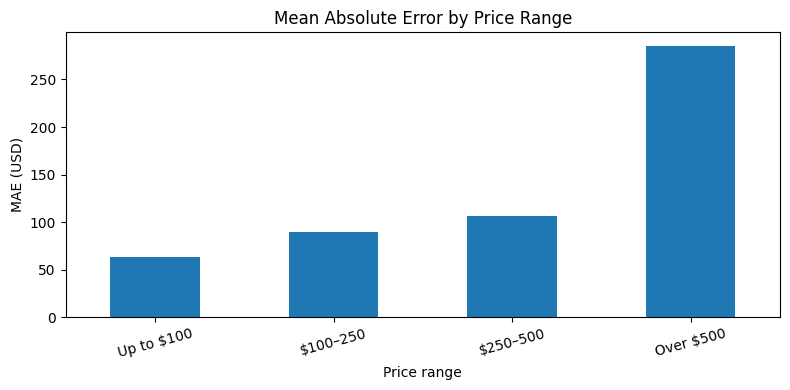

In [32]:
error_by_range.plot(kind='bar', figsize=(8, 4))
plt.title('Mean Absolute Error by Price Range')
plt.ylabel('MAE (USD)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Interpretación:** el R² resume el rendimiento global, pero aquí vemos para qué tipo de propiedades la herramienta podría equivocarse más. En el dashboard conviene comunicar esa incertidumbre.

## 5 · Comprobar que el filtro no esconda errores
Hacemos una **prueba de sensibilidad**: entrenamos otra versión con todos los precios positivos de hosts 1–2, incluso los outliers y las estancias largas. Es una población diferente, por eso no comparamos sus R² como si fueran el mismo examen.

In [33]:
from sklearn.base import clone

all_prices_df = small_hosts.dropna(subset=feature_columns + ['price']).copy()
X_all = all_prices_df[feature_columns]
y_all = all_prices_df['price']

Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42
)

In [34]:
model_all = clone(model)
model_all.fit(Xa_train, ya_train)
pred_all = model_all.predict(Xa_test)

print('All-price test records:', len(ya_test))
print('All-price MAE: $', round(mean_absolute_error(ya_test, pred_all), 2))
print('All-price RMSE: $', round(np.sqrt(mean_squared_error(ya_test, pred_all)), 2))
print('All-price R²:', round(r2_score(ya_test, pred_all), 4))

All-price test records: 3261
All-price MAE: $ 182.34
All-price RMSE: $ 444.31
All-price R²: 0.3599


**Interpretación:** la diferencia entre ambos resultados nos dice si el desempeño depende de haber acotado el mercado. Para reportar un R² siempre tenemos que indicar **qué propiedades entraron al entrenamiento y a la prueba**.

## 6 · Clasificación de precios (regla del Project Charter)
Para las alertas del dashboard comparamos el precio actual con la **mediana de propiedades similares** (vecindario, tipo, recámaras y capacidad). Aplicamos la regla del ±10%.

Primero construimos la referencia **solo con las propiedades de entrenamiento**. Si un grupo tiene menos de 5 comparables, usamos la mediana de su vecindario; si tampoco existe, la mediana global del entrenamiento.

### 6.1 · Calcular medianas de comparables

In [35]:
group_cols = ['neighbourhood_model', 'property_type_model',
              'bedrooms', 'accommodates']
reference = df_model.loc[X_train.index, ['price'] + group_cols].copy()

market = reference.groupby(group_cols)['price'].agg(['median', 'count'])
neighborhood_medians = reference.groupby('neighbourhood_model')['price'].median()

In [36]:
classified = df_model.loc[X_test.index, ['id', 'price'] + group_cols].copy()
classified = classified.join(market, on=group_cols)

fallback = classified['neighbourhood_model'].map(neighborhood_medians)
classified['market_median'] = classified['median'].where(
    classified['count'] >= 5, fallback
).fillna(reference['price'].median())

display(classified[['price', 'market_median']].head())

,price,market_median
4381,212.00,186.60
14677,226.85,132.62
9442,405.61,692.67
11501,204.50,236.50
14876,156.67,220.50


### 6.2 · Aplicar las tres categorías
Si el precio está entre 90% y 110% de la mediana comparable es **Competitive**. Fuera del intervalo indicamos la dirección del ajuste sugerido.

In [37]:
classified['price_ratio'] = classified['price'] / classified['market_median']

classified['pricing_alert'] = np.select(
    [classified['price_ratio'] < 0.90, classified['price_ratio'] > 1.10],
    ['Opportunity to Charge More', 'Too High'],
    default='Competitive'
)

display(classified[['price', 'market_median', 'pricing_alert']].head())

,price,market_median,pricing_alert
4381,212.00,186.60,Too High
14677,226.85,132.62,Too High
9442,405.61,692.67,Opportunity to Charge More
11501,204.50,236.50,Opportunity to Charge More
14876,156.67,220.50,Opportunity to Charge More


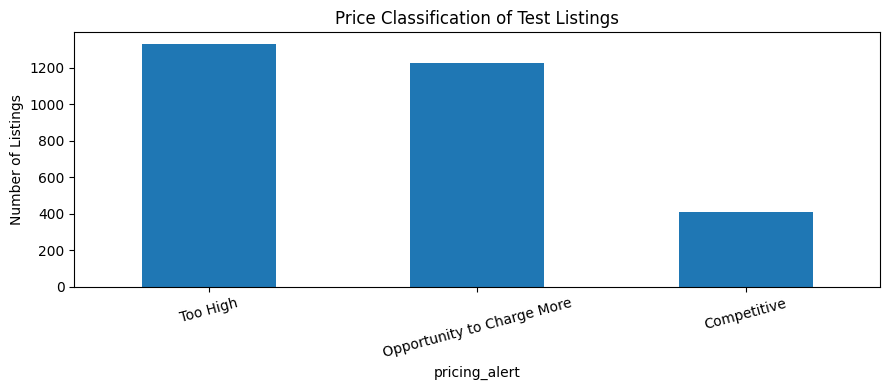

In [38]:
classified['pricing_alert'].value_counts().plot(kind='bar', figsize=(9, 4))
plt.title('Price Classification of Test Listings')
plt.ylabel('Number of Listings')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Importante:** estas alertas son **comparaciones de precios anunciados**, no una garantía de ocupación, ingresos o precio óptimo. Un clasificador entrenado para imitar esta misma regla no demostraría que las alertas sean correctas comercialmente.

## 7 · Preparar métricas y ejemplos (sin descargar todavía)
Guardamos aquí los resultados de regresión. **No descargamos nada todavía:** al final generaremos un solo ZIP con la base, ambos modelos, métricas, datos de referencia e instrucciones de integración.

In [39]:
import joblib
import json
import zipfile

joblib.dump(model, OUT_DIR / 'LA_LA_Stay_Ridge_Model.pkl')

metrics = pd.DataFrame([{
    'Model': f'Ridge alpha={best_alpha}',
    'MAE': mae, 'RMSE': rmse, 'R2': r2,
    'Train_rows': len(X_train), 'Test_rows': len(X_test)
}])
metrics.to_csv(OUT_DIR / 'LA_LA_Stay_Metrics.csv', index=False)

In [40]:
results = classified[['id', 'price', 'market_median', 'pricing_alert']].copy()
results['predicted_price'] = y_pred
results['absolute_error'] = abs(results['price'] - results['predicted_price'])
results.to_csv(OUT_DIR / 'LA_LA_Stay_Predictions.csv', index=False)

five_examples = results.sample(n=5, random_state=42)
display(five_examples.round(2))
five_examples.to_csv(OUT_DIR / 'LA_LA_Stay_5_Examples.csv', index=False)

,id,price,market_median,pricing_alert,predicted_price,absolute_error
2740,15330079,174.00,162.66,Competitive,190.27,16.27
14118,1232808802337696000,104.30,224.00,Opportunity to Charge More,249.67,145.37
2544,15665925,165.93,188.96,Opportunity to Charge More,236.65,70.72
4028,24812060,95.67,243.31,Opportunity to Charge More,172.85,77.18
17554,1588348922734589952,242.25,206.75,Too High,525.10,282.85


In [41]:
model_info = {
    'source': 'listings_clean (2).xlsx, Clean data',
    'features': feature_columns,
    'target': 'price',
    'scope': 'hosts 1–2, positive prices, price_outlier=0, long_stay=0',
    'model': f'Ridge(alpha={best_alpha})',
    'market_comparison': group_cols,
    'classification_thresholds': [0.90, 1.10],
    'test_R2': float(r2)
}
with open(OUT_DIR / 'LA_LA_Stay_Model_Info.json', 'w') as f:
    json.dump(model_info, f, indent=2)

---
## 8 · Classification Model — entrenar y evaluar

**Qué hacemos:** aplicamos la regla del Project Charter: un precio es *Competitive* si queda entre 90% y 110% de la mediana de anuncios comparables, *Too High* si la supera y *Opportunity to Charge More* si es menor.

El árbol de decisión aprende esa regla a partir de `price_ratio` (precio actual / mediana comparable). Las medianas del conjunto de prueba se calculan **solo con anuncios de entrenamiento** para no usar sus precios como referencia.

**Aclaración:** una accuracy muy alta significa que el árbol reproduce una regla creada por nosotros, no que hayamos comprobado que el precio es el mejor para el mercado.

### 8.1 · Etiquetas de entrenamiento a partir de precios comparables

In [42]:
# Calculamos la mediana de comparables para cada propiedad de entrenamiento.
train_compare = reference.join(market, on=group_cols)
train_neighborhood = reference['neighbourhood_model'].map(neighborhood_medians)
train_median = train_compare['median'].where(
    train_compare['count'] >= 5, train_neighborhood
).fillna(reference['price'].median())

train_ratio = reference['price'] / train_median
train_labels = np.select(
    [train_ratio < 0.90, train_ratio > 1.10],
    ['Opportunity to Charge More', 'Too High'], default='Competitive'
)
print('Training examples:', len(train_ratio))


Training examples: 11860


### 8.2 · Entrenar y guardar el clasificador

In [43]:
from sklearn.tree import DecisionTreeClassifier
classification_model = DecisionTreeClassifier(max_depth=2, random_state=42)
classification_model.fit(
    pd.DataFrame({'price_ratio': train_ratio}), train_labels
)
print('Classifier trained successfully!')

import joblib
joblib.dump(classification_model, OUT_DIR / 'LA_LA_Stay_Classification_Model.pkl')
print('Classification model saved')


Classifier trained successfully!
Classification model saved


### 8.3 · Evaluar accuracy, precision, recall y F1-score en el 20% de prueba

In [44]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
class_test_X = classified[['price_ratio']]
class_test_y = classified['pricing_alert']
class_pred = classification_model.predict(class_test_X)

class_results = {
    'Accuracy': accuracy_score(class_test_y, class_pred),
    'Precision': precision_score(class_test_y, class_pred, average='weighted'),
    'Recall': recall_score(class_test_y, class_pred, average='weighted'),
    'F1-score': f1_score(class_test_y, class_pred, average='weighted')
}
display(pd.DataFrame([class_results]).round(4))
print('Test records:', len(class_test_y))


,Accuracy,Precision,Recall,F1-score
0,1.0,1.0,1.0,1.0


Test records: 2965


### 8.4 · Matriz de confusión

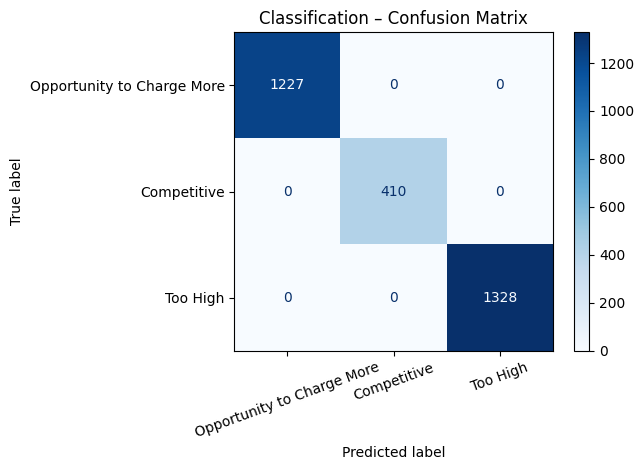

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay
classes = ['Opportunity to Charge More', 'Competitive', 'Too High']
ConfusionMatrixDisplay.from_predictions(
    class_test_y, class_pred, labels=classes,
    cmap='Blues', xticks_rotation=20
)
plt.title('Classification – Confusion Matrix')
plt.tight_layout()
plt.show()


**Interpretación:** si la accuracy es casi 100%, el árbol replica muy bien el umbral ±10%. **No** demuestra que esos precios aumenten reservas; la clasificación usa etiquetas calculadas mediante una regla que establecimos nosotros.

---
## 11 · Exportar los dos modelos y los archivos para el dashboard

Guardamos ambos `.pkl`, la base limpia, los comparables de entrenamiento, los resultados y un archivo con las variables y los límites de clasificación. El ZIP se descarga de una sola vez.


---
## 9 · Pruebas interactivas (una celda por modelo)

Modificamos los controles `#@param` de Google Colab y pulsamos **▶**. No necesitamos entrenar de nuevo.

- **Regression:** carga `LA_LA_Stay_Ridge_Model.pkl` y estima el precio con las variables del Excel nuevo. Los scores de amenities que no editamos se toman de propiedades similares del entrenamiento.
- **Classification:** carga `LA_LA_Stay_Classification_Model.pkl` y devuelve la categoría. Mostramos también la regla exacta ±10% para comprobar que coincidan.

**Importante:** para probar valores razonables, escribe categorías presentes en `neighbourhood_model` y `property_type_model`.

### 9.1 · Test interactivo de **regresión**

In [46]:
#@title 1. Probar REGRESIÓN (precio estimado)
import joblib
import pandas as pd

reg_neighbourhood = "Hollywood" #@param {type:"string"}
reg_property_type = "Entire home" #@param {type:"string"}
reg_bedrooms = 1 #@param {type:"integer", min:0}
reg_accommodates = 2 #@param {type:"integer", min:1}
reg_pool = False #@param {type:"boolean"}
reg_parking = True #@param {type:"boolean"}
reg_air_conditioning = True #@param {type:"boolean"}
reg_real_price = 0 #@param {type:"number", min:0}

# Cargamos el modelo Ridge guardado al final del entrenamiento.
regression_model = joblib.load(OUT_DIR / 'LA_LA_Stay_Ridge_Model.pkl')

# Las categorías deben existir en la nueva base.
if reg_neighbourhood not in X_train['neighbourhood_model'].values:
    raise ValueError('Neighborhood not found. Check neighbourhood_model in the data.')
if reg_property_type not in X_train['property_type_model'].values:
    raise ValueError('Property type not found. Check property_type_model in the data.')

# Buscamos propiedades similares SOLO en entrenamiento para tomar
# valores realistas de los otros indicadores de amenities.
similar = X_train[
    (X_train['neighbourhood_model'] == reg_neighbourhood) &
    (X_train['property_type_model'] == reg_property_type)
]
if len(similar) < 5:
    similar = X_train[X_train['property_type_model'] == reg_property_type]
    print('Amenities baseline: same property type (wider group).')
else:
    print('Amenities baseline: same neighborhood and property type.')

# Usamos la mediana de los scores como perfil base.
amenity_features = [
    col for col in X_train.columns
    if col not in ['bedrooms', 'accommodates',
                   'neighbourhood_model', 'property_type_model']
]
profile = similar[amenity_features].median().round().to_dict()

# Construimos una sola propiedad con todas las variables requeridas.
profile.update({
    'neighbourhood_model': reg_neighbourhood,
    'property_type_model': reg_property_type,
    'bedrooms': reg_bedrooms,
    'accommodates': reg_accommodates,
    'has_pool': int(reg_pool),
    'has_parking': int(reg_parking),
    'has_ac': int(reg_air_conditioning)
})
new_listing = pd.DataFrame([profile])[X_train.columns]

predicted_price = float(regression_model.predict(new_listing)[0])
print(f'\nPredicted nightly price: ${predicted_price:,.2f} USD')
print('Inputs:', reg_neighbourhood, '|', reg_property_type,
      '| Bedrooms:', reg_bedrooms, '| Guests:', reg_accommodates)

if reg_real_price > 0:
    print(f'Real/current price: ${reg_real_price:,.2f} USD')
    print(f'Difference: ${reg_real_price - predicted_price:,.2f} USD')

if predicted_price <= 0:
    print('Warning: unusual prediction. Try a more typical listing.')

Amenities baseline: same neighborhood and property type.

Predicted nightly price: $205.26 USD
Inputs: Hollywood | Entire home | Bedrooms: 1 | Guests: 2


### 9.2 · Test interactivo del **clasificador entrenado**

In [47]:
#@title 2. Probar CLASIFICACIÓN (alerta de precio)
import pandas as pd

cls_neighbourhood = "Hollywood" #@param {type:"string"}
cls_property_type = "Entire home" #@param {type:"string"}
cls_bedrooms = 1 #@param {type:"integer", min:0}
cls_accommodates = 2 #@param {type:"integer", min:1}
cls_current_price = 200 #@param {type:"number", min:0}

if cls_current_price <= 0:
    raise ValueError('Enter a current nightly price greater than zero.')

# 'reference' fue creada en el paso 6.1 solo con entrenamiento.
comparable = reference[
    (reference['neighbourhood_model'] == cls_neighbourhood) &
    (reference['property_type_model'] == cls_property_type) &
    (reference['bedrooms'] == cls_bedrooms) &
    (reference['accommodates'] == cls_accommodates)
]

if len(comparable) >= 5:
    market_median = float(comparable['price'].median())
    comparison_used = f'{len(comparable)} similar listings'
else:
    neighbourhood_listings = reference[
        reference['neighbourhood_model'] == cls_neighbourhood
    ]
    if len(neighbourhood_listings) > 0:
        market_median = float(neighbourhood_listings['price'].median())
        comparison_used = 'neighborhood median (fallback)'
    else:
        market_median = float(reference['price'].median())
        comparison_used = 'overall training median (fallback)'

lower_limit = market_median * 0.90
upper_limit = market_median * 1.10

if cls_current_price < lower_limit:
    classification = 'Opportunity to Charge More'
elif cls_current_price > upper_limit:
    classification = 'Too High'
else:
    classification = 'Competitive'

print('CLASSIFICATION RESULT')
print('-----------------------------')
print('Reference:', comparison_used)
print(f'Market median: ${market_median:,.2f} USD')
print(f'Competitive range: ${lower_limit:,.2f} to ${upper_limit:,.2f} USD')
print(f'Current nightly price: ${cls_current_price:,.2f} USD')
print('Exact ±10% classification:', classification)

# The trained classification model only needs the price ratio
import joblib
classification_model = joblib.load(OUT_DIR / 'LA_LA_Stay_Classification_Model.pkl')
price_ratio = cls_current_price / market_median
model_alert = classification_model.predict(
    pd.DataFrame({'price_ratio': [price_ratio]})
)[0]
print('Trained model classification:', model_alert)
if model_alert != classification:
    print('Warning: near a threshold, the tree can differ from the exact rule.')
print(f'Difference from market median: {100 * (cls_current_price / market_median - 1):+.1f}%')

CLASSIFICATION RESULT
-----------------------------
Reference: 5 similar listings
Market median: $175.86 USD
Competitive range: $158.27 to $193.45 USD
Current nightly price: $200.00 USD
Exact ±10% classification: Too High
Trained model classification: Too High
Difference from market median: +13.7%


**Para integrar el dashboard:** podemos utilizar el clasificador entrenado como entregable académico, pero las alertas visibles deben usar preferentemente la regla exacta ±10%. Si los resultados difieren cerca de un límite, mostramos la regla exacta.

---
## 10 · Preparar la entrega final para el otro equipo

Los siguientes bloques generan **todos** los archivos desde la nueva base. Al terminar habrá **una sola descarga** de un ZIP; al descomprimirlo quedarán archivos sueltos, listos para enviarse por WhatsApp sin carpetas.

No enviar los CSV del primer notebook: corresponden al dataset anterior.

### 10.1 · Guardar dos modelos y bases de datos

In [48]:
import joblib

joblib.dump(model, OUT_DIR / 'LA_LA_Stay_Ridge_Model.pkl')
joblib.dump(classification_model, OUT_DIR / 'LA_LA_Stay_Classification_Model.pkl')

df_model.to_csv(OUT_DIR / 'LA_LA_Stay_Clean_Training_Dataset.csv', index=False)
reference.to_csv(OUT_DIR / 'LA_LA_Stay_Market_Reference.csv', index=False)
X_train.to_csv(OUT_DIR / 'LA_LA_Stay_Regression_Input_Reference.csv', index=False)
print('2 models + 3 data files saved')

2 models + 3 data files saved


### 10.2 · Guardar resultados, métricas y matriz de confusión

In [49]:
from sklearn.metrics import confusion_matrix

pd.DataFrame([class_results]).to_csv(OUT_DIR / 'LA_LA_Stay_Classification_Metrics.csv', index=False)
pd.DataFrame(
    confusion_matrix(class_test_y, class_pred, labels=classes),
    index=classes, columns=classes
).to_csv(OUT_DIR / 'LA_LA_Stay_Confusion_Matrix.csv')

# Actualizamos la documentación con los resultados recién calculados
model_info.update({
    'classification_feature': ['price_ratio'],
    'min_comparables': 5,
    'classification_metrics': {k: float(v) for k,v in class_results.items()},
    'regression_metrics': {'MAE': float(mae), 'RMSE': float(rmse), 'R2': float(r2)},
    'train_rows': int(len(X_train)),
    'test_rows': int(len(X_test))
})
with open(OUT_DIR / 'LA_LA_Stay_Model_Info.json', 'w', encoding='utf-8') as f:
    json.dump(model_info, f, indent=2, ensure_ascii=False)
print('Evaluation files saved')

Evaluation files saved


### 10.3 · Data dictionary y cleaning report de la base ACTUAL

In [50]:
descriptions = {
    'price': 'Nightly listing price in USD (prediction target)',
    'id': 'Unique Airbnb listing identifier',
    'bedrooms': 'Number of bedrooms',
    'accommodates': 'Guest capacity',
    'neighbourhood_model': 'Clean neighborhood used by models',
    'property_type_model': 'Clean property type used by models',
    'amenities_count': 'Number of amenities',
    'price_outlier': 'Price outlier flag provided in the clean Excel',
    'long_stay': 'Long-stay flag provided in the clean Excel'
}

variable_dictionary = pd.DataFrame({
    'column': df_model.columns,
    'type': [str(df_model[col].dtype) for col in df_model.columns],
    'description': [descriptions.get(col, 'Cleaned source variable / amenity indicator')
                    for col in df_model.columns],
    'used_in_regression': [col in feature_columns for col in df_model.columns]
})
variable_dictionary.to_csv(OUT_DIR / 'LA_LA_Stay_Data_Dictionary.csv', index=False)

cleaning_report = pd.DataFrame([
    ('Rows in updated Excel', len(df)),
    ('Rows with positive price', len(with_price)),
    ('Rows for hosts with 1–2 listings', len(small_hosts)),
    ('Rows after excluding flagged outliers and long stays', len(df_clean)),
    ('Rows with complete predictors / final modeling data', len(df_model)),
    ('Rows excluded between eligible hosts and final modeling data', len(small_hosts)-len(df_model)),
    ('Regression train rows', len(X_train)),
    ('Regression test rows', len(X_test)),
    ('IDs duplicated in source before cleaning', original_duplicates)
], columns=['metric', 'value'])
cleaning_report.to_csv(OUT_DIR / 'LA_LA_Stay_Cleaning_Report.csv', index=False)
print('Data Dictionary and Cleaning Report saved')

Data Dictionary and Cleaning Report saved


### 10.4 · Instrucciones para integrar los modelos

In [51]:
import sklearn
from importlib.metadata import version

requirements = (f'pandas=={pd.__version__}\n'
                f'numpy=={np.__version__}\n'
                f'scikit-learn=={sklearn.__version__}\n'
                f'joblib=={version("joblib")}\n'
                f'openpyxl=={version("openpyxl")}\n')
with open(OUT_DIR / 'requirements.txt', 'w') as f:
    f.write(requirements)

readme = '''# LA LA Stay — Files for Dashboard Team

## Current dataset
All files here were generated using `listings_clean (2).xlsx` (sheet: Clean data).
Do NOT mix them with `airbnb_la_*` files from the old cleaning notebook.

## Regression: LA_LA_Stay_Ridge_Model.pkl
Load with joblib.load(). Accepts exactly the columns listed under `features`
in LA_LA_Stay_Model_Info.json. The `.pkl` contains a preprocessing pipeline.
Use LA_LA_Stay_Regression_Input_Reference.csv for valid category values
and realistic median baseline scores for remaining amenity inputs.
The predictions are USD per night and may be negative for unusual inputs:
validate the user inputs and flag implausible predictions.

## Classification: LA_LA_Stay_Classification_Model.pkl
The trained tree accepts a ONE-column DataFrame: `price_ratio`.
Calculate `market_median` from LA_LA_Stay_Market_Reference.csv using:
neighbourhood_model, property_type_model, bedrooms, accommodates.
If the exact group contains fewer than 5 listings, use the neighbourhood
median; if unavailable use the overall training median.
price_ratio = current_price / market_median.
Thresholds: <0.9 => Opportunity to Charge More; >1.1 => Too High;
otherwise Competitive. For production alerts use the exact rule.

The high classifier accuracy only measures how well the tree copies the
threshold rule, NOT real pricing accuracy or expected occupancy.

## Evaluation
LA_LA_Stay_Metrics.csv: MAE, RMSE and R2 for regression (20% holdout).
LA_LA_Stay_Classification_Metrics.csv and LA_LA_Stay_Confusion_Matrix.csv:
accuracy, precision, recall, F1 and confusion matrix (20% holdout).
The regression metrics apply only to hosts 1-2, positive prices, flagged
outliers removed, and long stays removed. No booking or revenue guarantees.

## 5 Examples
LA_LA_Stay_5_Examples.csv includes five test cases.

## Notebook
Share the notebook `.ipynb` as a separate WhatsApp document.
It's the reproducible source and visualization walkthrough.

## Compatibility
Install the versions in requirements.txt before loading `.pkl` files.
'''
with open(OUT_DIR / 'README_integracion.md', 'w', encoding='utf-8') as f:
    f.write(readme)
print('README and requirements saved')

README and requirements saved


### 10.5 · Descargar **UN SOLO ZIP** (archivos sueltos, sin carpetas)

In [52]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

file_list = [
    'LA_LA_Stay_Ridge_Model.pkl',
    'LA_LA_Stay_Classification_Model.pkl',
    'LA_LA_Stay_Clean_Training_Dataset.csv',
    'LA_LA_Stay_Market_Reference.csv',
    'LA_LA_Stay_Regression_Input_Reference.csv',
    'LA_LA_Stay_Model_Info.json',
    'LA_LA_Stay_Metrics.csv',
    'LA_LA_Stay_Classification_Metrics.csv',
    'LA_LA_Stay_Confusion_Matrix.csv',
    'LA_LA_Stay_Predictions.csv',
    'LA_LA_Stay_5_Examples.csv',
    'LA_LA_Stay_Data_Dictionary.csv',
    'LA_LA_Stay_Cleaning_Report.csv',
    'README_integracion.md',
    'requirements.txt'
]

missing = [name for name in file_list if not (OUT_DIR / name).is_file()]
if missing:
    raise FileNotFoundError('Files not created: ' + ', '.join(missing))

zip_filename = OUT_DIR / 'LA_LA_Stay_Entrega_Final_2_Modelos.zip'
with ZipFile(zip_filename, 'w', ZIP_DEFLATED) as package:
    for name in file_list:
        package.write(OUT_DIR / name, arcname=name)

print('Package ready:', zip_filename)
print('Files included:', len(file_list))
try:  # la descarga automática solo existe en Google Colab
    from google.colab import files
    files.download(str(zip_filename))
except ImportError:
    print('ZIP guardado en:', zip_filename)

Package ready: LA_LA_Stay_Entrega_Final_2_Modelos.zip
Files included: 15


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 11 · Conclusiones y checklist de entrega

**Qué demostramos:** exploramos cómo cambian los precios según recámaras, zona, tipo de propiedad, capacidad y amenities. Evaluamos Ridge con un holdout 80/20 y documentamos el efecto de filtrar precios extremos y estancias largas. Entrenamos y evaluamos un segundo modelo que aprende las tres clases de la regla ±10%.

**Limitaciones:** R² no indica porcentaje de aciertos. La clasificación aprende una etiqueta construida con la propia regla, por lo que su accuracy no demuestra rentabilidad ni demanda. Las estimaciones corresponden a precios anunciados en el dataset, no a reservas realizadas.

**Para entregar por WhatsApp:** (1) descomprime el ZIP y manda los archivos necesarios individualmente, (2) comparte este notebook `.ipynb` por separado, (3) comparte el README primero para explicar cómo integrar los dos `.pkl`. **No mezcles CSV del primer notebook**, porque pertenecen a la base anterior.